In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# use seaborn plotting defaults
import seaborn as sns; sns.set()

#### Working with Non-linear dataset

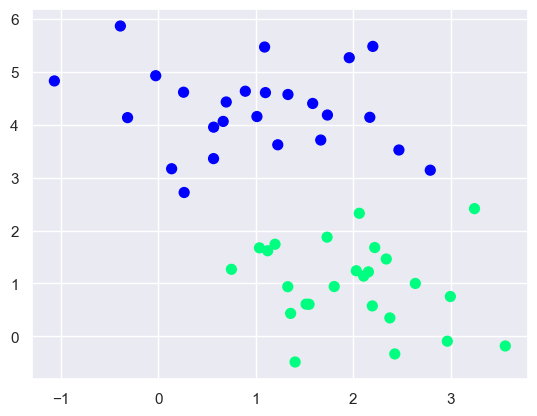

In [2]:
from sklearn.datasets._samples_generator import make_blobs

X,y = make_blobs(n_samples= 50, centers= 2, random_state= 0, cluster_std= 0.8)
plt.scatter(X[:,0], X[:, 1], c = y, s = 50, cmap = "winter")
plt.show()

In [3]:
from sklearn.svm import SVC # "Support vector classifier"
model = SVC(kernel='linear', C=10)
model.fit(X, y)

SVC(C=10, kernel='linear')

In [4]:
model.support_vectors_

array([[0.26604148, 2.71915015],
       [2.79207378, 3.14029479],
       [2.06366754, 2.32636006]])

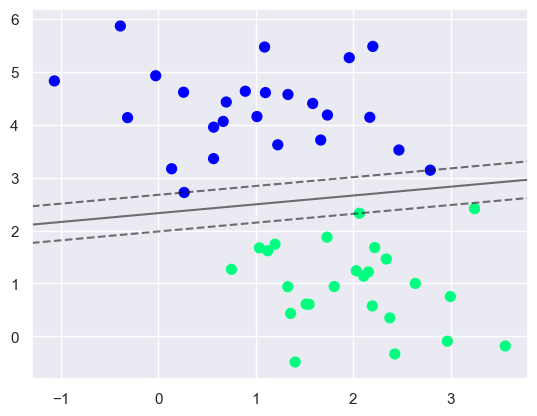

In [5]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    """Plot the decision function for a 2D SVC"""
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # create grid to evaluate model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)  # meshgrid reshapes 1D array to 2d array
    xy = np.vstack([X.ravel(), Y.ravel()]).T # vstack stacks two arrays vertically
    P = model.decision_function(xy).reshape(X.shape)
    
    # plot decision boundary and margins
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha= 0.6,
               linestyles=['--', '-', '--'])
    
    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='winter')
plot_svc_decision_function(model);

#### The importance of Support Vectors

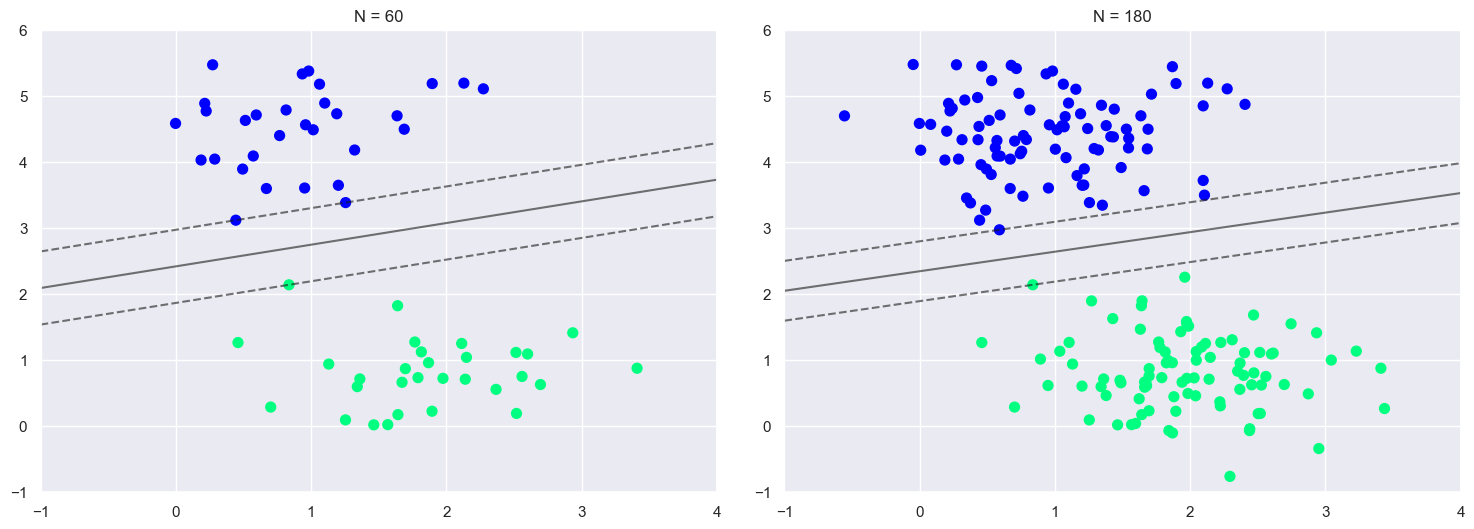

In [6]:
def plot_svm(N=20, ax=None):
    X, y = make_blobs(n_samples=200, centers=2,
                      random_state=0, cluster_std=0.60)
    X = X[:N]
    y = y[:N]
    model = SVC(kernel='linear', C=1E10)
    model.fit(X, y)
    
    ax = ax or plt.gca() ## if ax is,instead None plt.gca() gets stored. 
    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='winter')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 180]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))

#### Working with Almost Linearly Separable Dataset

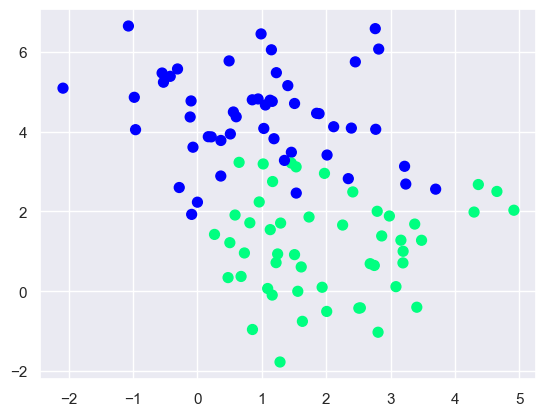

In [7]:

X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='winter');

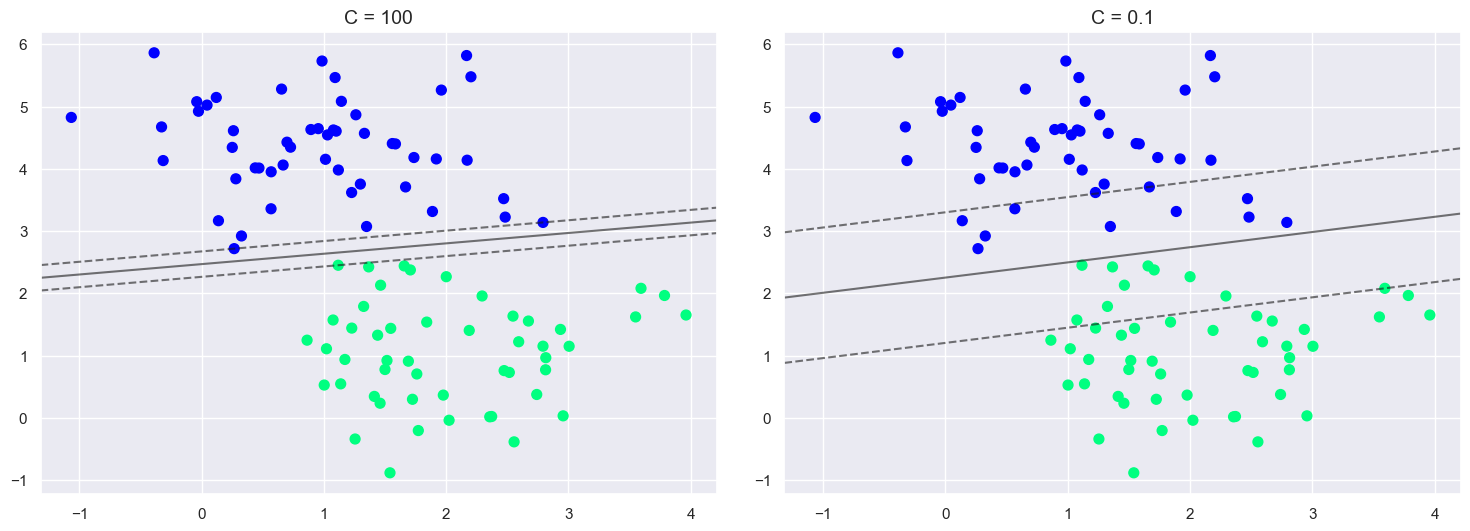

In [8]:
X,y = make_blobs(n_samples= 100, centers = 2, 
                 random_state= 0, cluster_std= 0.8)
fig,ax = plt.subplots(1,2, figsize = (16,6))
fig.subplots_adjust(left = 0.0625, right = 0.95, wspace= 0.1)

for axi, C in zip(ax, [100, 0.1]):
    model = SVC(kernel = 'linear', C = C)
    model.fit(X,y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='winter')
    plot_svc_decision_function(model, axi)
    axi.set_title('C = {0}'.format(C), size=14)

### From book chapter-5

In [9]:
from sklearn.datasets import load_iris
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

iris = load_iris(as_frame= True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris.target == 2 # Iris virginica

svm_cls = make_pipeline(StandardScaler(),
                        LinearSVC(C = 1, random_state= 42))

svm_cls.fit(X,y)

c:\Users\Anwoy\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('linearsvc', LinearSVC(C=1, random_state=42))])

In [10]:
X_new = [[5.5, 1.7], [5.0, 1.5]]
svm_cls.predict(X_new) # is it Iris virginica?

array([ True, False])

In [11]:
svm_cls.decision_function(X_new)
# decision function is used find the signed distance between each instance and the decision boundary.

array([ 0.66163411, -0.22036063])

#### Nonlinear SVM Classification

In [12]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import PolynomialFeatures

X, y = make_moons(n_samples=100, noise=0.15, random_state=42)

polynomial_svm_clf = make_pipeline(
    PolynomialFeatures(degree=3),
    StandardScaler(),
    LinearSVC(C=10, max_iter=10_000, dual=True, random_state=42)
)
polynomial_svm_clf.fit(X, y)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=3)),
                ('standardscaler', StandardScaler()),
                ('linearsvc',
                 LinearSVC(C=10, dual=True, max_iter=10000, random_state=42))])

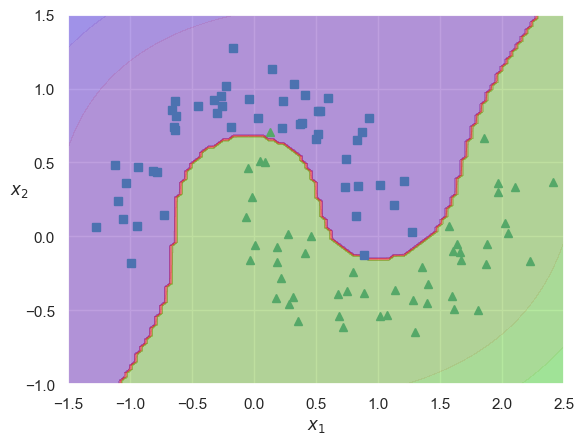

In [13]:
def plot_dataset(X, y, axes):
    plt.plot(X[:, 0][y==0], X[:, 1][y==0], "bs")
    plt.plot(X[:, 0][y==1], X[:, 1][y==1], "g^")
    plt.axis(axes)
    plt.grid(True)
    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$", rotation=0)

def plot_predictions(clf, axes):
    x0s = np.linspace(axes[0], axes[1], 100)
    x1s = np.linspace(axes[2], axes[3], 100)
    x0, x1 = np.meshgrid(x0s, x1s) 
    X = np.c_[x0.ravel(), x1.ravel()]
    y_pred = clf.predict(X).reshape(x0.shape)
    y_decision = clf.decision_function(X).reshape(x0.shape)
    plt.contourf(x0, x1, y_pred, cmap=plt.cm.brg, alpha=0.3) #Didn't understand why we need so complex calculation(above) for this plot?
    plt.contourf(x0, x1, y_decision, cmap=plt.cm.brg, alpha=0.1)

plot_predictions(polynomial_svm_clf, [-1.5, 2.5, -1, 1.5])
plot_dataset(X, y, [-1.5, 2.5, -1, 1.5])

#### Polynomial Kernel

In [14]:
from sklearn.svm import SVC

poly_kernel_svm_clf = make_pipeline(StandardScaler(),
                                    SVC(kernel="poly", degree=3, coef0=1, C=5))
poly_kernel_svm_clf.fit(X, y)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(C=5, coef0=1, kernel='poly'))])

In [15]:
y_pred = poly_kernel_svm_clf.predict(X)
from sklearn.metrics import accuracy_score
accuracy_score(y, y_pred)

0.98

Text(0, 0.5, '')

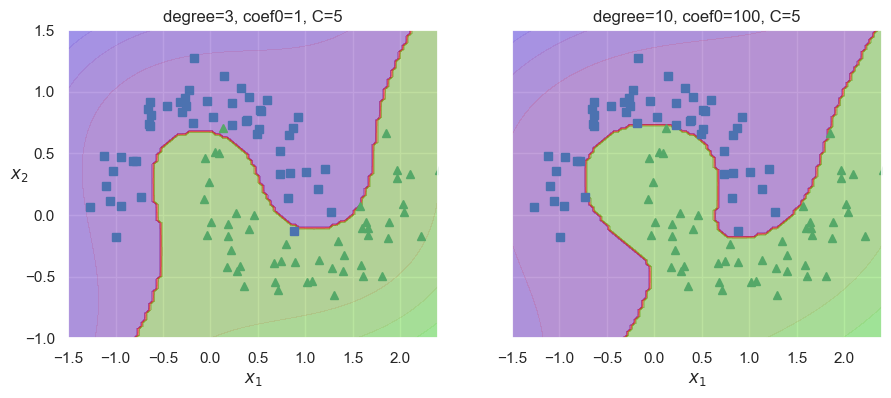

In [16]:
poly100_kernel_svm_clf = make_pipeline(
    StandardScaler(),
    SVC(kernel="poly", degree=10, coef0=100, C=5)
)
poly100_kernel_svm_clf.fit(X, y)

fig, axes = plt.subplots(ncols=2, figsize=(10.5, 4), sharey=True)

plt.sca(axes[0])
plot_predictions(poly_kernel_svm_clf, [-1.5, 2.45, -1, 1.5])
plot_dataset(X, y, [-1.5, 2.4, -1, 1.5])
plt.title("degree=3, coef0=1, C=5")

plt.sca(axes[1])
plot_predictions(poly100_kernel_svm_clf, [-1.5, 2.45, -1, 1.5])
plot_dataset(X, y, [-1.5, 2.4, -1, 1.5])
plt.title("degree=10, coef0=100, C=5")
plt.ylabel("")

##### coef0 controls how much the model is influnced by high-degree terms versus low-degree terms.
##### Changing it creates different decision boundary.

In [17]:
y_pred2 = poly100_kernel_svm_clf.predict(X) 
accuracy_score(y, y_pred2)

# Model with 10 degree and higher coefficients are performing well for this dataset.

1.0

#### Gaussian RBF function

In [18]:
from sklearn.svm import SVC
gamma1, gamma2 = 0.1, 5
C1, C2 = 0.001, 1000
hyperps = (gamma1, C1), (gamma1, C2), (gamma2, C1), (gamma2, C2)

svm_clfs = []
for gamma, C in hyperps:
    svm_rbf_cls = make_pipeline(
        StandardScaler(),
        SVC(kernel ="rbf", gamma = gamma, C = C)
    )
    svm_rbf_cls.fit(X,y)
    svm_clfs.append(svm_rbf_cls)

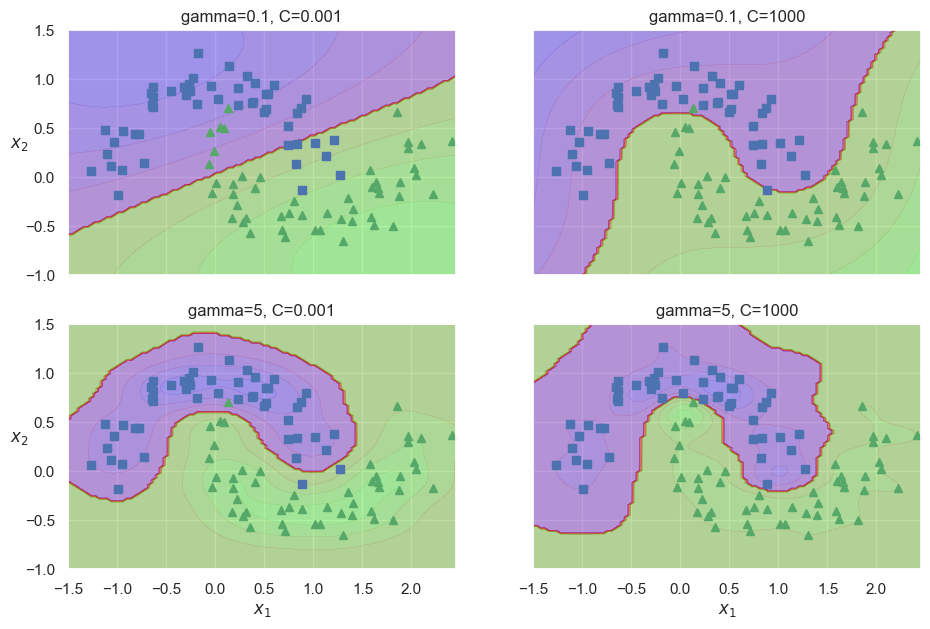

In [19]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(11, 7), sharex=True, sharey=True)

for i, svm_clf in enumerate(svm_clfs):
    plt.sca(axes[i // 2, i % 2])
    plot_predictions(svm_clf, [-1.5, 2.45, -1, 1.5])
    plot_dataset(X, y, [-1.5, 2.45, -1, 1.5])
    gamma, C = hyperps[i]
    plt.title(f"gamma={gamma}, C={C}")
    if i in (0, 1):
        plt.xlabel("")
    if i in (1, 3):
        plt.ylabel("")


#### Support Vector Regression

In [20]:
from sklearn.svm import LinearSVR

np.random.seed(42)
X = 2* np.random.rand(50,1)
y = 4 + X[:, 0] + np.random.rand(50)

svm_reg = make_pipeline(
            StandardScaler(),
            LinearSVR(epsilon= 0.5, random_state= 42)
)

svm_reg.fit(X,y)

c:\Users\Anwoy\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('linearsvr', LinearSVR(epsilon=0.5, random_state=42))])

#### Exercise of chapter 5: Question 9

In [43]:
from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.linear_model import SGDClassifier
from sklearn.datasets import load_iris
import pandas as pd

In [207]:
# keep only setosha and versicolor data.
iris = load_iris(as_frame= True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris.target

X = X[y !=2]
y = y[y!=2]

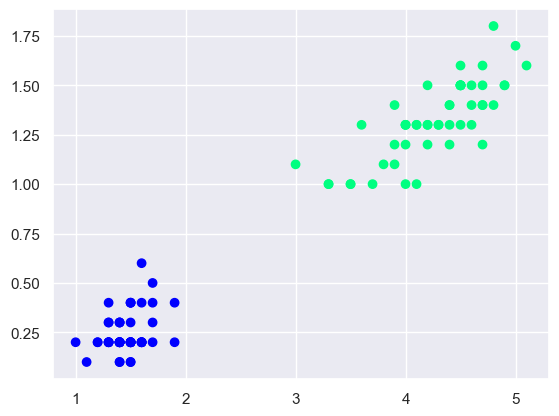

In [208]:
plt.scatter(X[:,0], X[:,1], c= y, cmap= 'winter')

In [209]:
C = 5
alpha = 0.05

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

lin_clf = LinearSVC(loss="hinge", C=C, dual=True, random_state=42).fit(X_scaled, y)
svc_clf = SVC(kernel="linear", C=C).fit(X_scaled, y)
sgd_clf = SGDClassifier(alpha=alpha, random_state=42).fit(X_scaled, y)

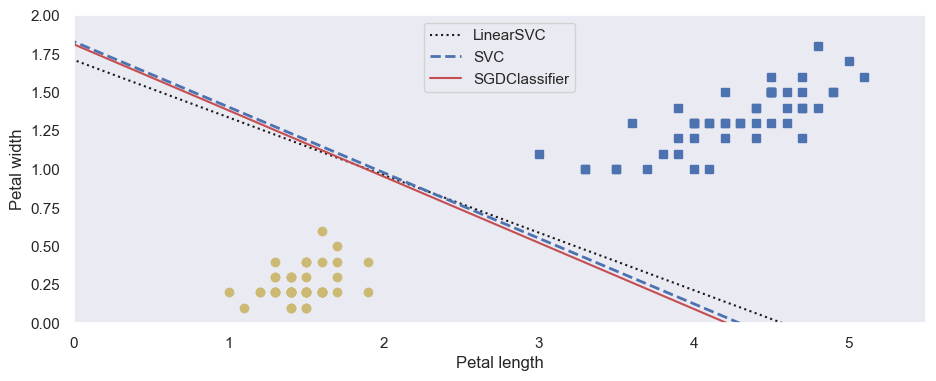

In [211]:

def compute_decision_boundary(model):
    w = -model.coef_[0, 0] / model.coef_[0, 1] # finds the slope
    b = -model.intercept_[0] / model.coef_[0, 1] # finds the intercept term
    return scaler.inverse_transform([[-10, -10 * w + b], [10, 10 * w + b]]) # transforming scaled values into their original form
                                       ## The above matrix was used to create 2 data points for plotting a line.         

lin_line = compute_decision_boundary(lin_clf)
svc_line = compute_decision_boundary(svc_clf)
sgd_line = compute_decision_boundary(sgd_clf)

# Plot all three decision boundaries
plt.figure(figsize=(11, 4))
plt.plot(lin_line[:, 0], lin_line[:, 1], "k:", label="LinearSVC")
plt.plot(svc_line[:, 0], svc_line[:, 1], "b--", linewidth=2, label="SVC")
plt.plot(sgd_line[:, 0], sgd_line[:, 1], "r-", label="SGDClassifier")
plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs") # label="Iris versicolor"
plt.plot(X[:, 0][y==0], X[:, 1][y==0], "yo") # label="Iris setosa"
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="upper center")
plt.axis([0, 5.5, 0, 2])
plt.grid()

plt.show()


#### Exercise: Question no 10

In [135]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame= True)

X = wine.data
y = wine.target

In [137]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42)

In [148]:
Xtrain_scaled2 = scaler.fit_transform(X_train)
Xtest_scaled2 = scaler.transform(X_test)

wine_svc = SVC(kernel = 'linear', C = 10, random_state= 42)
wine_svc.fit(Xtrain_scaled2, y_train)

SVC(C=1000, kernel='linear', random_state=42)

In [149]:
y_pred = wine_svc.predict(Xtest_scaled2)

accuracy_score(y_test.ravel(), y_pred)

0.9777777777777777

##### Using SVM with rbf kernel using hypertuning

In [151]:
from sklearn.model_selection import cross_val_score

svm_clf = make_pipeline(StandardScaler(), SVC(random_state= 10))
cross_val_score(svm_clf, X_train, y_train).mean()

0.9698005698005698

In [157]:
from sklearn.model_selection import RandomizedSearchCV  
from scipy.stats import loguniform, uniform

para_distr = {
    "svc__gamma" : loguniform(0.0001, 0.1),
    "svc__C" : uniform(1, 10)
}
rdn_svm_cv = RandomizedSearchCV(svm_clf, para_distr, 
                                n_iter= 100, cv = 5)
rdn_svm_cv.fit(Xtrain_scaled2, y_train)
rdn_svm_cv.best_estimator_

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc',
                 SVC(C=4.764633668780496, gamma=0.02701842272864324,
                     random_state=10))])

In [159]:
rdn_svm_cv.best_score_

0.9851851851851852

In [162]:
rdn_svm_cv.score(X_test, y_test) ## test score for unscaled data

c:\Users\Anwoy\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:458: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


0.4

In [161]:
rdn_svm_cv.score(Xtest_scaled2, y_test) ### test score for scaled data.

0.9777777777777777

##### Question no 11

In [163]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()
X = housing.data
y = housing.target

In [186]:
X_train, X_test, y_train, y_test = train_test_split(X,y, random_state= 42)

In [202]:

from sklearn.svm import SVR
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, uniform
from sklearn.metrics import mean_squared_error

svm_reg = make_pipeline(StandardScaler(), SVR())

param_distrib = {
    "svr__gamma": loguniform(0.001, 0.1),
    "svr__C": uniform(1, 10)
}
rnd_search_cv = RandomizedSearchCV(svm_reg, param_distrib,
                                   n_iter=100, cv=3, random_state=42)
rnd_search_cv.fit(X_train[:2000], y_train[:2000])

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('standardscaler',
                                              StandardScaler()),
                                             ('svr', SVR())]),
                   n_iter=100,
                   param_distributions={'svr__C': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x000001B187555C10>,
                                        'svr__gamma': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x000001B1980A5CD0>},
                   random_state=42)

In [200]:
rnd_search_cv.best_estimator_

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svr', SVR(C=4.63629602379294, gamma=0.08781408196485979))])

In [203]:
-cross_val_score(rnd_search_cv.best_estimator_, X_train, y_train,
                 scoring="neg_root_mean_squared_error")

array([-0.60444605, -0.56694363, -0.58737987, -0.56849629, -0.60171446])

In [204]:
y_pred = rnd_search_cv.best_estimator_.predict(X_test)
rmse = mean_squared_error(y_test, y_pred, squared=False)
rmse

0.578287154631978